In [2]:
import sys
from pathlib import Path

# The notebook runs inside notebooks/, but our package lives in the project root.
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.data.warehouse import load_orders

In [3]:
orders = load_orders()
print(orders.shape)
print(orders["order_ts"].min(), "→", orders["order_ts"].max())
orders.head()

(36969, 6)
2009-12-01 07:45:00 → 2011-12-09 12:50:00


,customer_id,invoice_no,order_ts,order_value,items,lines
0,12346,491725,2009-12-14 08:34:00,45.0,10,1
1,12346,491742,2009-12-14 11:00:00,22.5,5,1
2,12346,491744,2009-12-14 11:02:00,22.5,5,1
3,12346,492718,2009-12-18 10:47:00,22.5,5,1
4,12346,492722,2009-12-18 10:55:00,1.0,1,1


In [8]:
# One row per customer per purchase DAY: two invoices on the same day are one shopping trip.
purchase_days = (
    orders.assign(order_date=orders["order_ts"].dt.normalize())[["customer_id", "order_date"]]
    .drop_duplicates()
)

# diff() within each customer = days since that customer's previous purchase day
purchase_days["gap_days"] = purchase_days.groupby("customer_id")["order_date"].diff().dt.days
gaps = purchase_days["gap_days"].dropna()

print(gaps.describe(percentiles=[0.5, 0.75, 0.8, 0.9, 0.95]).round(1))

count    27229.0
mean        59.0
std         78.3
min          1.0
50%         31.0
75%         70.0
80%         87.0
90%        147.0
95%        221.0
max        714.0
Name: gap_days, dtype: float64


In [9]:
for window in [30, 60, 90, 120, 180]:
    share = (gaps <= window).mean()
    print(f"{window:>4} days: {share:.1%} of returns happen within the window")

  30 days: 49.3% of returns happen within the window
  60 days: 71.0% of returns happen within the window
  90 days: 80.7% of returns happen within the window
 120 days: 86.6% of returns happen within the window
 180 days: 92.8% of returns happen within the window


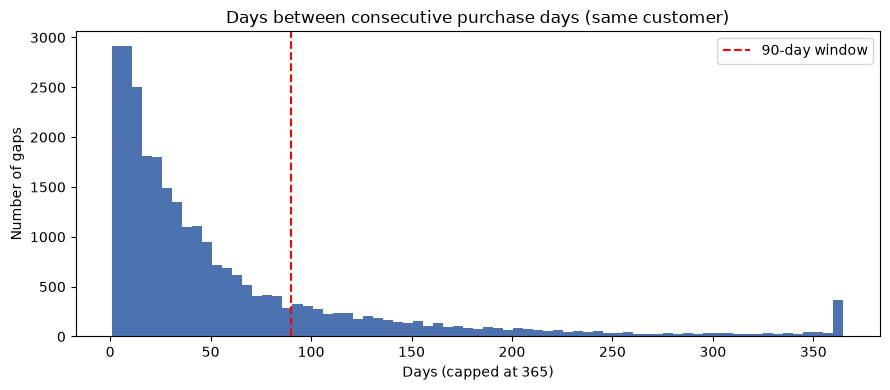

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(gaps.clip(upper=365), bins=73, color="#4C72B0")
ax.axvline(90, color="red", linestyle="--", label="90-day window")
ax.set(
    title="Days between consecutive purchase days (same customer)",
    xlabel="Days (capped at 365)",
    ylabel="Number of gaps",
)
ax.legend()
fig.tight_layout()
fig.savefig(PROJECT_ROOT / "docs" / "purchase_gaps.png", dpi=120)
plt.show()

In [11]:
from src.features.labels import make_churn_labels

for cutoff in ["2011-06-11", "2011-09-10"]:
    labels = make_churn_labels(orders, cutoff=cutoff)
    print(f"cutoff {cutoff}: {len(labels):,} customers, churn rate {labels['churned'].mean():.1%}")

cutoff 2011-06-11: 4,338 customers, churn rate 64.2%
cutoff 2011-09-10: 4,317 customers, churn rate 49.4%
